In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statistics as st
import pickle

import warnings

from tqdm.notebook import tqdm
from scipy.stats import beta
from scipy import stats
from scipy import integrate
from scipy import special
from concurrent.futures import ProcessPoolExecutor

In [2]:
#Simulation_itelation

rep_sim = 1000
rep_sim = 100000
rep_sim = 445000
rep_sim = 528400

In [3]:
# Difinition of Runge-Kutta methods

def rk4 ( y, t, h, f ):
    k1 = h * f( y, t )
    k2 = h * f( y + k1/2, t + h/2 )
    k3 = h * f( y + k2/2, t + h/2 )
    k4 = h * f( y + k3, t + h )
    return  y + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h

In [4]:
# Seed definitions

def SEEDS(seed):
    seeds = seed
    if seeds > 2**32 - 1:
        seeds = seeds/0.9 - 2**32
        if seeds > 2**32 - 1:
            seeds = seeds/0.9 - 2**32
            if seeds > 2**32 - 1:
                seeds = seeds/0.9 - 2**32
    np.random.seed(round(seeds))
    DecidedSeed = np.random.randint(0, 2**32)
    return DecidedSeed

In [5]:
# Difinition of PERT distribution

def PERT(a,b,c):
    return a+(c-a)*np.random.beta(1+4*(b-a)/(c-a), 1+4*(c-b)/(c-a))

In [6]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (Normal dist.)
#メトロポリスヘイスティング (正規分布)
def Metropolis_Hastings_norm(Temp_mean, sigma_Temp, Time_end, Temp0):
    Time_end = round(Time_end,1)
    def f(x):
        return stats.norm.pdf(x, Temp_mean, sigma_Temp)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    y = Temp0
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [7]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (PERT dist.)
#メトロポリスヘイスティング　（PERT分布）
def Metropolis_Hastings_pert(Temp_min, Temp_med, Temp_max, Time_end, Temp0):
    Time_end = round(Time_end,1)
    alpha = 1+4*(Temp_med-Temp_min)/(Temp_max-Temp_min)
    beta = 1+4*(Temp_max-Temp_med)/(Temp_max-Temp_min)

    def f(x):
        x_pert = (x - Temp_min)/(Temp_max-Temp_min)
        return stats.beta.pdf(x_pert, alpha, beta)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    
    if Temp0 > Temp_max:
        Temp0pert = Temp_max
    if Temp0 < Temp_min:
        Temp0pert = Temp_min
    else:
        Temp0pert = Temp0
    
    y = Temp0pert
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [8]:
def Mass_lettuce():  # This study
    return PERT(300, 480, 650)

In [9]:
def Prev_Init_Letuce(m_lettuce):
    # Prevalence (Wjinand, 2014)
    Pre_P = np.random.beta(3+1,1810-3+1)
    CheckLettuceContami = np.random.binomial(n = 1, p = Pre_P)
    
    # Initial Count (logCFU/g) (Wjinand, 2014)
    logC_initial = np.random.normal(0.10, 0.21)
    
    if CheckLettuceContami == 0:
        logC_initial = -float('inf')
    
    return Pre_P, CheckLettuceContami, logC_initial # (-), logcfu/g

In [10]:
def Prev_Init_Meat():
    ID_choice = 0
    if ID_choice == 0:
        # Prevalence (Food Safety Commission of Japan, 2016)
        Pre_P = PERT(0.32, 0.658, 0.96)
        CheckMeatContami = np.random.binomial(n = 1, p = Pre_P)

        # Initial Count (log CFU/g) (Ono, 2004; log CFU/100g)
        
        X = [np.log10(5.5)-1.5-2, np.log10(5.5)+0.5-2, np.log10(5.5)+1.5-2, np.log10(5.5)+2.5-2, np.log10(5.5)+3.5-2, np.log10(5.5)+5.5-2]
        P = [0, 25, 47.7, 76.6, 96.9, 100]

        p = np.random.uniform(np.min(P), np.max(P))

        for i in range(len(P)):
            if not i==np.max(range(len(P))):
                if ((P[i]<= p)&(p<P[i+1])):
                    logC_initial = np.random.uniform(X[i], X[i+1])
        if CheckMeatContami == 0:
            logC_initial = -float('inf')
    
    return Pre_P, CheckMeatContami, logC_initial # (-), logcfu/g

In [11]:
def rk4_Baranyi_dqdt(q, t, h, mu_max):
    def f (q, t):
        return mu_max * q
    k1 = h * f( q, t )
    k2 = h * f( q + k1/2, t + h/2 )
    k3 = h * f( q + k2/2, t + h/2 )
    k4 = h * f( q + k3, t + h )
    return  q + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
def rk4_Baranyi_Baranyi_dCdt(C, t, h, mu_max, q, Cmax):
    def f (C, t):
        return mu_max * q / (1+q) * (1 - C/Cmax) * C
    k1 = h * f( C, t )
    k2 = h * f( C + k1/2, t + h/2 )
    k3 = h * f( C + k2/2, t + h/2 )
    k4 = h * f( C + k3, t + h )
    return  C + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
    
def Differential_Baranyi_dqdt(q, mu_max):  ### q description
    return mu_max * q
    
def Differential_Baranyi_dCdt(C, mu_max, q, Cmax):  ### Natural log
    return mu_max * q / (1+q) * (1 - C/Cmax) * C


In [12]:
def Cross_probs():
    CheckLettuceAfterMeat = 0
    X_meat2uten  = CheckLettuceAfterMeat * np.random.beta(0.33+1, 0.53) # ??? Dharod et al., 2009???
    X_meat2hand  = CheckLettuceAfterMeat * np.min([np.random.lognormal(0.94, 0.68)/100, 1])
    X_uten2hand  = CheckLettuceAfterMeat * np.random.beta(0.33+1, 0.53)
    CheckHandWash = np.random.binomial(1, 0.748)
    if CheckHandWash == 1:
        X_reduc_wash  = CheckLettuceAfterMeat*np.min([np.random.lognormal(-0.20, 1.42)/100, 1])
    if CheckHandWash == 0:
        X_reduc_wash  = CheckLettuceAfterMeat*1
    X_hand2lettuce = CheckLettuceAfterMeat * np.min([np.random.lognormal(-0.80, 1.09)/100, 1])
    
    return X_meat2uten, X_meat2hand, X_uten2hand, X_reduc_wash, X_hand2lettuce, CheckHandWash, CheckLettuceAfterMeat

In [13]:
def lettuceWash():
    CheckLettuceWash = np.random.binomial(1, 1-0.366)
    reduc_lettuce_wash = PERT(10**(3.5-5.4), 10**(4.2-5.0), 1)**(CheckLettuceWash)#Uhlig et al.,2017
    return CheckLettuceWash, reduc_lettuce_wash

In [14]:
def DRmodel_Appro_Beta_Pois(Dose):
    alpha_BetaPois = 0.057 #Teunis et al., 2005
    beta_BetaPois = 0.047 #Teunis et al., 2005
    P_DR = 1.0 - (1+Dose/beta_BetaPois)**-alpha_BetaPois #Approximate Beta-Poisson DR model
    return P_DR

In [15]:
def ServeSize(m_lettuce):
    servesize = m_lettuce/round(m_lettuce/85) # 85g of mean size FDA???
    return servesize # g

In [16]:
def PackSize_Meat():
    return PERT(150, 200, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)
def ServeSize_Meat():
    return PERT(50, 85, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)

In [17]:
def determineInfection(P_inf):
    return np.random.binomial(1, P_inf)

In [18]:
def QMRA_calculations(ID_sim):
    ### Setting of the seed for the random numbers
    np.random.seed(SEEDS(19990128+ID_sim))
    
    ### Weight of lettuce
    m_lettuce = Mass_lettuce()
    m_meat = PackSize_Meat()
    
    ### Prevalence and Initial conc.
    p_lettuce, checklettuce0, logC0_lettuce = Prev_Init_Letuce(m_lettuce) # Lettuce
    p_meat, checkmeat0, logC0_meat  = Prev_Init_Meat() # meat
    
    ### Initial count in lettuce
    N0 = m_lettuce * 10**logC0_lettuce # CFU
    N0 = np.random.poisson(N0) # CFU
    logN0 = np.log10(N0) # logCFU
    logC0_lettuce = np.log10(N0/m_lettuce) # logCFU/g
    
    ### Initial count in meat
    N0_meat = m_meat * 10**logC0_meat # CFU
    N0_meat = np.random.poisson(N0_meat) # CFU
    logN0_meat = np.log10(N0_meat) # logCFU
    logC0_meat = np.log10(N0_meat/m_meat) # logCFU/g
    
    
    ### No growth during storage
    N_home_lettuce = N_trans_lettuce = N0
    logC_home_lettuce = logC_trans_lettuce = logC0_lettuce
    
    N_home_meat = N_trans_meat = N0_meat
    logC_home_meat = logC_trans_meat = logC0_meat
    
    
    ### Cross contaminations
    size_meat = np.min([ServeSize_Meat(), m_meat]) # g
    
    x_meat2uten, x_meat2hand, x_uten2hand, x_reduc_wash, x_hand2lettuce, checkhandwash, checklettuceaftermeat = Cross_probs()
    
    contami_meat = np.random.binomial(N_home_meat, size_meat/m_meat) #CFU/meat serve
    
    xcontami_meat2uten = np.random.binomial(contami_meat, x_meat2uten) #CFU
    xcontami_uten2hand = np.random.binomial(xcontami_meat2uten, x_uten2hand) #CFU
    xcontami_meat2hand = np.random.binomial(contami_meat, x_meat2hand) #CFU
    xcontami_hand = xcontami_uten2hand + xcontami_meat2hand #CFU
    xcontami_washed_hand = np.random.binomial(xcontami_hand, x_reduc_wash) #CFU
    xcontami_hand2lettuce = np.random.binomial(xcontami_washed_hand, x_hand2lettuce) #CFU
    
    ### Consumption
    size_serve = ServeSize(m_lettuce)
    
    contami_lettuce = np.random.binomial(N_home_lettuce, size_serve/m_lettuce)
    contami_lettuce_before_wash = contami_lettuce + xcontami_hand2lettuce
    
    ### Lettuce wash
    checklettucewash, reduc_lettuce_wash = lettuceWash()
    finalcontami_lettuce = np.random.binomial(contami_lettuce_before_wash, reduc_lettuce_wash) #CFU
    
    dose = finalcontami_lettuce
    logdose = np.log10(dose)
    
    ### Infection or not
    p_DR = DRmodel_Appro_Beta_Pois(dose)
    p_inf = p_DR
    checkInf = determineInfection(p_inf)
    
    ### Output selection
    output = pd.DataFrame({
        "checkInf": [checkInf],
        "m_lettuce": [round(m_lettuce,2)],
        "m_meat": [round(m_meat,2)],
        "p_lettuce": [round(p_lettuce,6)],
        "checklettuce0": [checklettuce0],
        "logC0_lettuce": [round(logC0_lettuce,2)],
        "p_meat": [round(p_meat,6)],
        "checkmeat0": [checkmeat0],
        "logC0_meat": [round(logC0_meat,2)],
        "logC_trans_lettuce": [round(logC_trans_lettuce,2)],
        "logC_home_lettuce": [round(logC_home_lettuce,2)],
        "logC_trans_meat": [round(logC_trans_meat,2)],
        "logC_home_meat": [round(logC_home_meat,2)],
        "size_meat": [round(size_meat,2)],
        "checklettuceaftermeat": [checklettuceaftermeat],
        "x_meat2uten": [round(x_meat2uten,6)],
        "x_meat2hand": [round(x_meat2hand,6)],
        "x_uten2hand": [round(x_uten2hand,6)],
        "x_reduc_wash": [round(x_reduc_wash,6)],
        "checkhandwash": [checkhandwash],
        "x_hand2lettuce": [round(x_hand2lettuce,6)],
        "contami_meat": [contami_meat],
        "xcontami_meat2uten": [xcontami_meat2uten],
        "xcontami_uten2hand": [xcontami_uten2hand],
        "xcontami_meat2hand": [xcontami_meat2hand],
        "xcontami_hand": [xcontami_hand],
        "xcontami_washed_hand": [xcontami_washed_hand],
        "xcontami_hand2lettuce": [xcontami_hand2lettuce],
        "contami_lettuce": [contami_lettuce],
        "size_serve": [round(size_serve,2)],
        "checklettucewash": [checklettucewash],
        "reduc_lettuce_wash": [round(reduc_lettuce_wash,6)],
        "logdose": [round(logdose,2)],
        "p_inf": [round(p_inf,4)]
    })
    return output

In [19]:
warnings.simplefilter('ignore', RuntimeWarning)
Sim_results =[]
ns = range(rep_sim)
with ProcessPoolExecutor(8) as e:
    ret = e.map(QMRA_calculations, ns)
Sim_results = [r for r in ret]
Sim_results = pd.concat(Sim_results)
Sim_results = Sim_results.reset_index()
Sim_results = Sim_results.drop(columns='index')

In [20]:
len(Sim_results)

528400

In [21]:
import datetime
with open('results/Simulation results of repsim no cross.pkl', 'wb') as g:
    pickle.dump(Sim_results, g)

In [22]:
np.sum(Sim_results["checkInf"])

409

In [23]:
Sim_results = pickle.load(open('results/Simulation results of repsim no cross.pkl', 'rb'))

In [24]:
Sim_results

,checkInf,m_lettuce,m_meat,p_lettuce,checklettuce0,logC0_lettuce,p_meat,checkmeat0,logC0_meat,logC_trans_lettuce,...,xcontami_meat2hand,xcontami_hand,xcontami_washed_hand,xcontami_hand2lettuce,contami_lettuce,size_serve,checklettucewash,reduc_lettuce_wash,logdose,p_inf
0,0,464.22,185.60,0.002303,0,-inf,0.742581,0,-inf,-inf,...,0,0,0,0,0,92.84,0,1.000000,-inf,0.0
1,0,452.40,178.70,0.001472,0,-inf,0.588134,1,-0.34,-inf,...,0,0,0,0,0,90.48,1,0.516896,-inf,0.0
2,0,443.26,191.01,0.001048,0,-inf,0.808561,0,-inf,-inf,...,0,0,0,0,0,88.65,1,0.117574,-inf,0.0
3,0,467.96,195.51,0.002699,0,-inf,0.542713,1,-0.97,-inf,...,0,0,0,0,0,77.99,1,0.209416,-inf,0.0
4,0,427.90,211.50,0.002452,0,-inf,0.616823,1,-inf,-inf,...,0,0,0,0,0,85.58,1,0.499513,-inf,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528395,0,483.03,210.17,0.003406,0,-inf,0.495561,0,-inf,-inf,...,0,0,0,0,0,80.50,1,0.060654,-inf,0.0
528396,0,568.14,169.88,0.001875,0,-inf,0.611255,1,1.51,-inf,...,0,0,0,0,0,81.16,0,1.000000,-inf,0.0
528397,0,533.18,171.73,0.004189,0,-inf,0.813008,1,0.60,-inf,...,0,0,0,0,0,88.86,0,1.000000,-inf,0.0
528398,0,456.34,166.67,0.002381,0,-inf,0.688052,1,1.09,-inf,...,0,0,0,0,0,91.27,0,1.000000,-inf,0.0


In [25]:
np.mean(Sim_results["p_inf"])

0.0007222469719909158

In [26]:
Sensitivity_corr = Sim_results.corr(method="spearman")
Sensitivity_corr["checkInf"].to_csv("results/Illness occurrence Spearman no cross.csv")
Sensitivity_corr["logdose"].to_csv("results/log dose Spearman no cross.csv")
Sensitivity_corr = Sensitivity_corr.reindex(Sensitivity_corr["checkInf"].abs().sort_values().index)

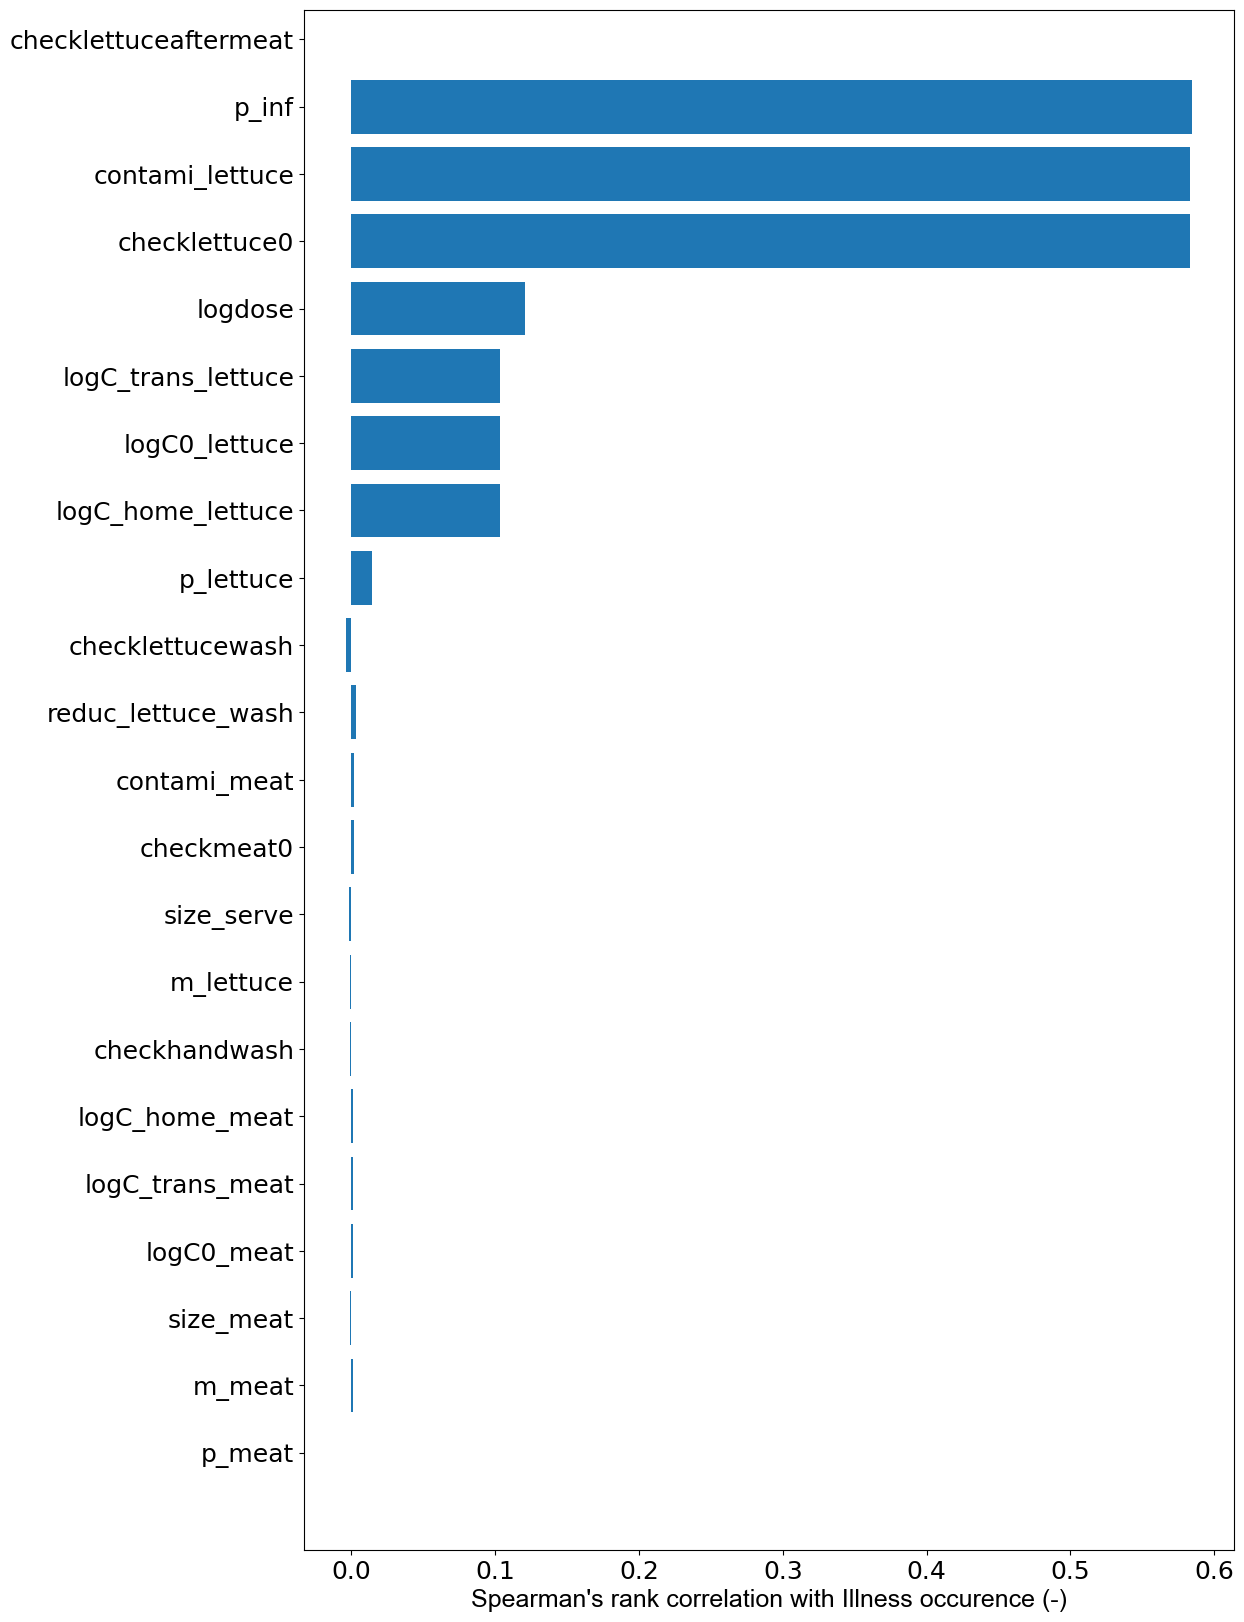

In [27]:
fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_corr.drop('checkInf', axis=0).index, 
        Sensitivity_corr.drop('checkInf', axis=0)["checkInf"])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with Illness occurence (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman.pdf", bbox_inches="tight", dpi=500)
plt.show()

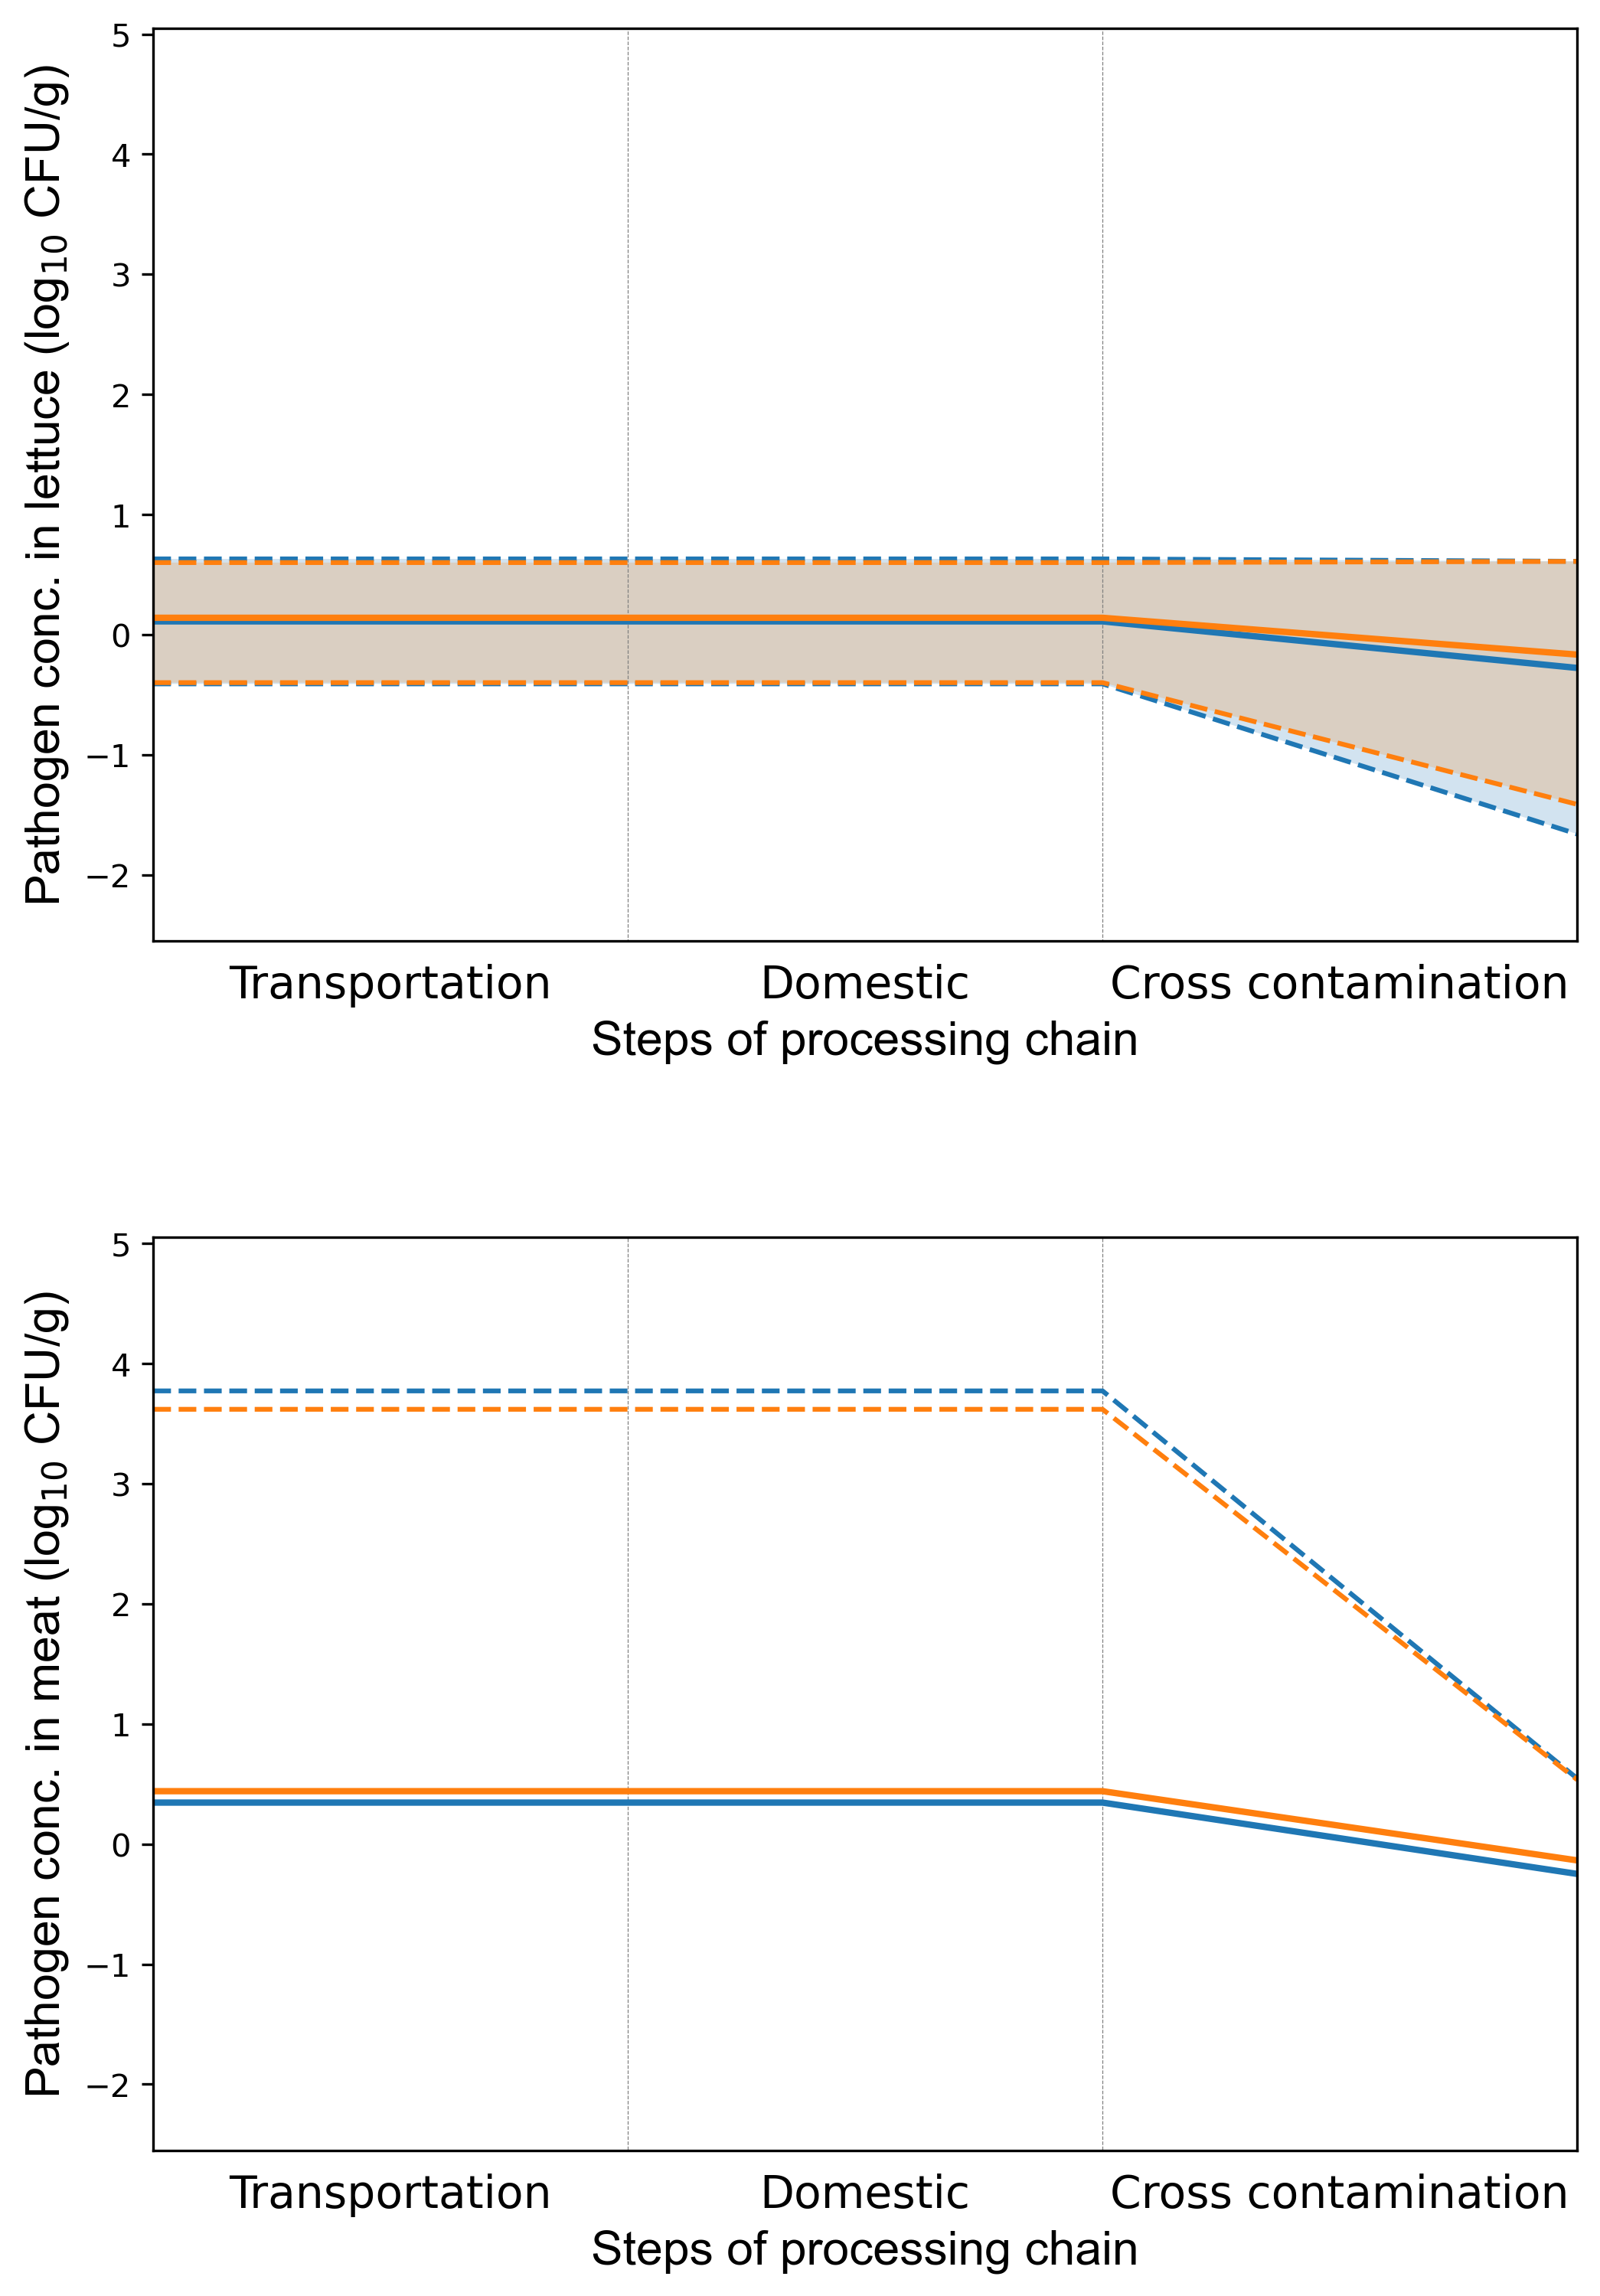

In [28]:
Palette=sns.color_palette(n_colors = 4)
logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC0_lettuce"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_trans_lettuce"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_home_lettuce"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["size_serve"])

logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))



fig, ax = plt.subplots(2, 1, gridspec_kw={'width_ratios': [1], 'height_ratios': [1, 1]},figsize=(8,12), dpi=300)
plt.subplots_adjust(wspace=0, hspace=0.325)
plt.rcParams["font.family"] = "Arial"


ax[0].set_xticks([0.5, 1.5, 2.5])
ax[0].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[0].tick_params(bottom=False)
ax[0].set_ylim([-2.55, 5.05])
ax[0].set_xlim([-0, 3])



ax[0].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[0].set_ylabel("Pathogen conc. in lettuce (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[0].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

ax[0].fill_between([0,1,2,3], 
                 [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], 
                 alpha=0.2)
ax[0].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)

#ax[0].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)

#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)].index:
#        ax[0].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)


ax[0].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')


ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')



logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC0_meat"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_trans_meat"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_home_meat"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["size_serve"])

logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))



ax[1].set_xticks([0.5, 1.5, 2.5])
ax[1].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[1].tick_params(bottom=False)
ax[1].set_ylim([-2.55, 5.05])
ax[1].set_xlim([-0, 3])



ax[1].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[1].set_ylabel("Pathogen conc. in meat (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[1].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

ax[1].fill_between([0,1,2,3], 
                 [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], 
                 alpha=0.2)

ax[1].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)

#ax[1].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)


#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)].index:
#        ax[1].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)

ax[1].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[1].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[1].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')



ax[1].plot([0,1,2,3], 
         [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
ax[1].plot([0,1,2,3], 
         [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
ax[1].plot([0,1,2,3], 
         [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')

plt.savefig("plot/Step and conc.pdf", bbox_inches="tight", dpi=500)
plt.show()


In [29]:
np.sum(Sim_results["checkInf"])

409

In [30]:
Sim_results["logdose"][Sim_results["logdose"]!=0]

0        -inf
1        -inf
2        -inf
3        -inf
4        -inf
         ... 
528395   -inf
528396   -inf
528397   -inf
528398   -inf
528399   -inf
Name: logdose, Length: 528395, dtype: float64

In [31]:
np.sum(Sim_results ["checkmeat0"])

344254

In [32]:
np.sum(Sim_results ["checklettuce0"])

1200

In [33]:
np.sum(Sim_results["checkInf"])

409

In [34]:
Sim_results[Sim_results["checkInf"]==1]["checkmeat0"]

26        1
815       1
2099      0
2360      1
2969      1
         ..
525582    0
525723    0
525943    1
527670    1
528073    1
Name: checkmeat0, Length: 409, dtype: int64

In [35]:
Sim_results[Sim_results["checkInf"]==1]["checklettuce0"]

26        1
815       1
2099      1
2360      1
2969      1
         ..
525582    1
525723    1
525943    1
527670    1
528073    1
Name: checklettuce0, Length: 409, dtype: int64

In [36]:
np.sum(Sim_results ["checkInf"])

409

(array([ 6., 19., 27., 38., 45., 67., 75., 65., 52., 15.]),
 array([0.48, 0.69, 0.9 , 1.11, 1.32, 1.53, 1.74, 1.95, 2.16, 2.37, 2.58]),
 <BarContainer object of 10 artists>)

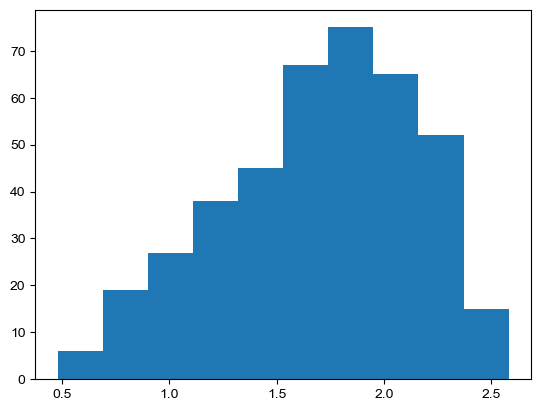

In [37]:
plt.hist(Sim_results["logdose"][Sim_results["checkInf"]==1])

In [38]:
np.sum(Sim_results["checklettuce0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

1.0

In [39]:
np.sum(Sim_results["checkmeat0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.6772616136919315

In [40]:
1-np.sum(Sim_results["checkhandwash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.2713936430317848

In [41]:
np.sum(Sim_results["checkInf"])

409

In [42]:
#病気の中のレタス有病率
np.sum(Sim_results["checklettuce0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

1.0

In [43]:
#感染の中の肉有病率
np.sum(Sim_results["checkmeat0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.6772616136919315

In [44]:
#感染の中の生肉を先に調理している確率
np.sum(Sim_results["checklettuceaftermeat"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.0

In [45]:
#感染の中の手洗いしていない率
1-np.sum(Sim_results["checkhandwash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.2713936430317848

(0.0, 1.0)

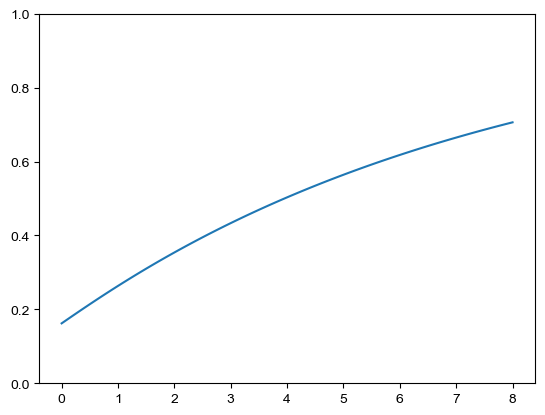

In [46]:
logdds = np.linspace(0, 8, int(8*10+1), endpoint = True)
probss = np.linspace(0, 8, int(8*10+1), endpoint = True)
for i in range (len(logdds)):
    probss[i] = DRmodel_Appro_Beta_Pois(10**logdds[i])
plt.plot(logdds, probss)
plt.ylim([0,1])